# Building a Basic RAG Pipeline with LangGraph and ChromaDB

## Introduction

Welcome to this tutorial on building a **Retrieval-Augmented Generation (RAG)** system! RAG is a powerful technique that combines information retrieval with large language models (LLMs) to create more accurate, grounded responses based on your own knowledge base.

### What You'll Learn

In this notebook, you will learn to:
- Understand the two-phase RAG architecture (indexing and querying)
- Work with embeddings and vector stores for semantic search
- Use ChromaDB as an in-memory vector database
- Build a simple LangGraph workflow with retrieve and generate nodes
- Create a working RAG pipeline from start to finish

### Prerequisites

- Basic Python knowledge
- Understanding of LLMs and prompts
- Familiarity with LangGraph basics (states and nodes)
- An OpenAI API key (for embeddings and LLM)

### What is RAG?

RAG (Retrieval-Augmented Generation) is a technique that enhances LLM responses by:
1. **Retrieving** relevant information from a knowledge base
2. **Augmenting** the LLM prompt with that retrieved context
3. **Generating** responses grounded in factual information

This approach helps prevent hallucinations and allows LLMs to answer questions about information they weren't trained on.

### The RAG Pipeline

```
INDEXING PHASE (Offline):
Documents → Split into Chunks → Generate Embeddings → Store in Vector DB

QUERY PHASE (Runtime):
User Query → Embed Query → Similarity Search → Retrieve Top-K → Augment Prompt → Generate Response
```

Let's build this step by step!

## 1. Setup and Installation

First, let's install the required packages and set up our environment.

In [12]:
# Install required packages
# Uncomment the line below if you need to install packages
# !pip install langchain langchain-openai langchain-chroma langchain-text-splitters langchain-core langgraph python-dotenv

### Import Required Libraries

We'll need:
- **LangChain Core**: For document processing and base abstractions
- **LangChain OpenAI**: For embeddings and language model
- **LangChain Chroma**: For our vector database integration
- **LangChain Text Splitters**: For chunking documents
- **LangGraph**: For building our RAG workflow
- **CSV**: For loading our data (built-in Python module)

In [ ]:
import os
import csv
from dotenv import load_dotenv
from typing import TypedDict, List

# LangChain imports
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

# LangGraph imports
from langgraph.graph import StateGraph, START, END

# Load environment variables
load_dotenv()

# Verify API key is loaded
if not os.getenv("OPENAI_API_KEY"):
    raise ValueError("OPENAI_API_KEY not found in environment variables. Please set it in your .env file.")

print("All libraries imported successfully!")
print("OpenAI API key loaded")

## 2. Load and Explore the Data

We'll use a collection of Paul Graham's essays as our knowledge base. These essays cover topics like startups, programming, and technology.

The CSV file contains:
- `id`: Unique identifier for each essay
- `title`: Essay title
- `date`: Publication date
- `text`: Full essay content

In [16]:
# Load the Paul Graham essays using Python's csv module
data_path = "pual_graham_essays.csv"

essays = []
with open(data_path, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        essays.append(row)

# Display basic information
print(f"Loaded {len(essays)} essays")
print(f"\nColumns: {list(essays[0].keys())}")
print(f"\nFirst few rows:")
for i, essay in enumerate(essays[:3]):
    print(f"\n{i+1}. {essay['title']} ({essay['date']})")

Loaded 215 essays

Columns: ['id', 'title', 'date', 'text']

First few rows:

1. The Age of the Essay (September 2004)

2. A Plan for Spam (August 2002)

3. The Trouble with the Segway (July 2009)


In [17]:
# Let's look at one essay to understand the content
sample_essay = essays[0]
print(f"Title: {sample_essay['title']}")
print(f"Date: {sample_essay['date']}")
print(f"\nFirst 500 characters of text:")
print(sample_essay['text'][:500] + "...")

Title: The Age of the Essay
Date: September 2004

First 500 characters of text:
Remember the essays you had to write in high school? Topic sentence, introductory paragraph, supporting paragraphs, conclusion. The conclusion being, say, that Ahab in _Moby Dick_ was a Christ-like figure.

Oy. So I'm going to try to give the other side of the story: what an essay really is, and how you write one. Or at least, how I write one.

**Mods**

The most obvious difference between real essays and the things one has to write in school is that real essays are not exclusively about English...


## 3. Indexing Phase: Building the Knowledge Base

The indexing phase is where we prepare our documents for retrieval. This happens **offline** (before any user queries) and consists of three main steps:

1. **Document Loading & Chunking**: Split large texts into smaller, manageable pieces
2. **Generate Embeddings**: Convert text chunks into numerical vectors that capture semantic meaning
3. **Store in Vector Database**: Save embeddings for efficient similarity search

### Why Chunking?

- LLMs have context limits
- Smaller chunks improve retrieval precision
- Each chunk can be independently searched and ranked
- Typical chunk size: 500-1500 characters with 10-20% overlap

### Step 3.1: Convert Data to LangChain Documents

LangChain's `Document` object holds:
- `page_content`: The actual text
- `metadata`: Additional information (title, date, source, etc.)

In [18]:
# Convert essays to LangChain Document objects
documents = []

for essay in essays:
    doc = Document(
        page_content=essay['text'],
        metadata={
            'title': essay['title'],
            'date': essay['date'],
            'essay_id': essay['id']
        }
    )
    documents.append(doc)

print(f"Created {len(documents)} documents")
print(f"\nExample document:")
print(f"Content length: {len(documents[0].page_content)} characters")
print(f"Metadata: {documents[0].metadata}")

Created 215 documents

Example document:
Content length: 26200 characters
Metadata: {'title': 'The Age of the Essay', 'date': 'September 2004', 'essay_id': '0'}


### Step 3.2: Split Documents into Chunks

We'll use `RecursiveCharacterTextSplitter` which:
- Splits text at natural boundaries (paragraphs, sentences)
- Maintains a target chunk size
- Creates overlap between chunks to preserve context

**Parameters:**
- `chunk_size=1000`: Target size for each chunk (in characters)
- `chunk_overlap=200`: Overlap between chunks (20% overlap helps maintain context)

In [19]:
# Initialize text splitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    length_function=len,
    separators=["\n\n", "\n", " ", ""]  # Try to split at paragraph, then line, then word
)

# Split all documents into chunks
chunks = text_splitter.split_documents(documents)

print(f"Original documents: {len(documents)}")
print(f"Total chunks after splitting: {len(chunks)}")
print(f"Average chunks per document: {len(chunks) / len(documents):.1f}")
print(f"\nExample chunk:")
print(f"Content: {chunks[0].page_content[:300]}...")
print(f"Metadata: {chunks[0].metadata}")

Original documents: 215
Total chunks after splitting: 3924
Average chunks per document: 18.3

Example chunk:
Content: Remember the essays you had to write in high school? Topic sentence, introductory paragraph, supporting paragraphs, conclusion. The conclusion being, say, that Ahab in _Moby Dick_ was a Christ-like figure.

Oy. So I'm going to try to give the other side of the story: what an essay really is, and how...
Metadata: {'title': 'The Age of the Essay', 'date': 'September 2004', 'essay_id': '0'}


### Step 3.3: Initialize Embeddings Model

**What are embeddings?**
Embeddings are numerical vectors that capture the semantic meaning of text. Similar concepts have similar vectors.

Examples:
- "dog" and "puppy" → close vectors
- "dog" and "car" → distant vectors

We'll use OpenAI's `text-embedding-3-small` model:
- Fast and cost-effective
- 1536 dimensions
- Good for most RAG applications

In [ ]:
# Initialize OpenAI embeddings
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

print("Embeddings model initialized")
print("Model: text-embedding-3-small")

# Optional: Test the embeddings with a sample text
sample_text = "What is a startup?"
sample_embedding = embeddings.embed_query(sample_text)
print(f"\nSample embedding dimensions: {len(sample_embedding)}")
print(f"First 5 values: {sample_embedding[:5]}")

### Step 3.4: Create Vector Store with ChromaDB via LangChain

Now we'll create our vector database using LangChain's Chroma integration. This will:
1. Initialize a Chroma vector store with our embeddings model
2. Store document chunks with their embeddings
3. Enable fast similarity search

**LangChain's Chroma integration** automatically handles:
- Generating embeddings for all chunks
- Storing embeddings along with text and metadata
- Managing the ChromaDB collection

**Note:** We're using in-memory mode by not specifying `persist_directory`. In production, you'd add `persist_directory="./chroma_db"` to persist the data to disk.

**This step takes a few moments** as it generates embeddings for all chunks.

In [ ]:
# Create vector store using LangChain's Chroma
print("Creating Chroma vector store... (this may take a minute)")

vectorstore = Chroma(
    collection_name="paul_graham_essays",
    embedding_function=embeddings,
    # persist_directory="./chroma_db"  # Uncomment to persist to disk
)

# Add all document chunks to the vector store
# This will automatically generate embeddings and store them
print("Adding documents and generating embeddings...")
vectorstore.add_documents(documents=chunks)

print(f"\nVector store created successfully!")
print(f"Total chunks indexed: {len(chunks)}")
print("\nThe indexing phase is complete. Your knowledge base is ready for queries!")

### Test the Vector Store

Let's test our vector store by performing a simple similarity search. This will show us that retrieval is working correctly.

In [31]:


# Test similarity search
test_query = "What makes a good startup idea?"

# Perform similarity search (returns Document objects)
results = vectorstore.similarity_search(test_query, k=3)

print(f"Query: '{test_query}'\n")
print(f"Found {len(results)} relevant chunks:\n")

for i, doc in enumerate(results, 1):
    print(f"--- Result {i} ---")
    print(f"Title: {doc.metadata.get('title', 'Unknown')}")
    print(f"Content preview: {doc.page_content[:200]}...")
    print()

Query: 'What makes a good startup idea?'

Found 3 relevant chunks:

--- Result 1 ---
Title: How to Get Startup Ideas
Content preview: The way to get startup ideas is not to try to think of startup ideas. It's to look for problems, preferably problems you have yourself.

The very best startup ideas tend to have three things in common...

--- Result 2 ---
Title: How to Get Startup Ideas
Content preview: Made-up startup ideas are usually of the first type. Lots of people are mildly interested in a social network for pet owners.

Nearly all good startup ideas are of the second type. Microsoft was a wel...

--- Result 3 ---
Title: How to Get Startup Ideas
Content preview: Finding startup ideas is a subtle business, and that's why most people who try fail so miserably. It doesn't work well simply to try to think of startup ideas. If you do that, you get bad ones that so...



## 4. Query Phase: Building the RAG Workflow

Now we'll build the **query phase** using LangGraph. This phase runs at runtime for each user question and consists of:

1. **Retrieve Node**: Find relevant document chunks
2. **Generate Node**: Create a response using retrieved context

### RAG State Definition

First, let's define our state. The state holds all the information that flows through our workflow nodes.

In [32]:
# Define the state that will be passed between nodes
class RAGState(TypedDict):
    """State for our RAG workflow."""
    query: str                    # User's question
    context: List[Document]       # Retrieved document chunks
    answer: str                   # Final generated answer

print("RAG state defined")
print("\nState fields:")
print("  - query: The user's question")
print("  - context: Retrieved relevant document chunks")
print("  - answer: The final LLM-generated response")

RAG state defined

State fields:
  - query: The user's question
  - context: Retrieved relevant document chunks
  - answer: The final LLM-generated response


### Node 1: Retrieve Documents

The retrieve node:
1. Takes the user query from the state
2. Embeds the query (converts to vector)
3. Performs similarity search in the vector store
4. Returns the top-k most relevant chunks

**Key Point:** We use the same embedding model for queries as we used for indexing. This ensures queries and documents exist in the same vector space.

In [33]:
def retrieve_node(state: RAGState) -> RAGState:
    """
    Retrieve relevant documents based on the query.
    
    This node:
    1. Takes the query from state
    2. Performs similarity search in the vector store
    3. Returns top 5 most relevant chunks as Document objects
    """
    query = state["query"]
    
    print(f"Retrieving documents for query: '{query}'")
    
    # Perform similarity search using LangChain's Chroma
    # k=5 means we retrieve the top 5 most relevant chunks
    retrieved_docs = vectorstore.similarity_search(query, k=5)
    
    print(f"Retrieved {len(retrieved_docs)} relevant documents")
    
    # Update state with retrieved context
    return {
        "query": query,
        "context": retrieved_docs,
        "answer": ""  # Will be filled by generate node
    }

print("Retrieve node defined")

Retrieve node defined


### Node 2: Generate Answer

The generate node:
1. Takes the query and retrieved context from state
2. Formats the context into a readable string
3. Creates a prompt that instructs the LLM to use the context
4. Calls the LLM to generate a grounded response

**The RAG Magic:** By providing retrieved context in the prompt, we ground the LLM's response in factual information from our knowledge base.

In [34]:
# Initialize the LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Create a prompt template for RAG
rag_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a helpful assistant answering questions about Paul Graham's essays.
    
Use the following context to answer the user's question. If you cannot answer the question based 
on the context, say so clearly. Always ground your answer in the provided context.

Context:
{context}
"""),
    ("human", "{query}")
])

def generate_node(state: RAGState) -> RAGState:
    """
    Generate an answer using retrieved context.
    
    This node:
    1. Formats retrieved documents as context
    2. Creates a prompt with context + query
    3. Calls LLM to generate grounded response
    """
    query = state["query"]
    context_docs = state["context"]
    
    print(f"Generating answer using {len(context_docs)} context chunks")
    
    # Format context: combine all retrieved documents
    context_text = "\n\n".join([
        f"[From '{doc.metadata.get('title', 'Unknown')}']\\n{doc.page_content}"
        for doc in context_docs
    ])
    
    # Create the prompt with context
    prompt = rag_prompt.invoke({
        "context": context_text,
        "query": query
    })
    
    # Generate response
    response = llm.invoke(prompt)
    answer = response.content
    
    print("Answer generated")
    
    # Update state with final answer
    return {
        "query": query,
        "context": context_docs,
        "answer": answer
    }

print("Generate node defined")

Generate node defined


### Build the LangGraph Workflow

Now we'll assemble our nodes into a workflow using LangGraph's `StateGraph`.

Our workflow is simple and linear:
```
START → retrieve → generate → END
```

This means:
1. Start with a query
2. Always retrieve context first
3. Then generate an answer
4. Return the final result

In [35]:
# Create the workflow
workflow = StateGraph(RAGState)

# Add nodes
workflow.add_node("retrieve", retrieve_node)
workflow.add_node("generate", generate_node)

# Define the flow
workflow.add_edge(START, "retrieve")        # Start by retrieving
workflow.add_edge("retrieve", "generate")   # Then generate answer
workflow.add_edge("generate", END)          # End after generating

# Compile the workflow
rag_app = workflow.compile()

print("RAG workflow compiled successfully!")
print("\nWorkflow structure:")
print("  START -> retrieve -> generate -> END")

RAG workflow compiled successfully!

Workflow structure:
  START -> retrieve -> generate -> END


### Visualize the Workflow (Optional)

LangGraph can generate a visual representation of your workflow. This helps you understand the flow of data through your nodes.

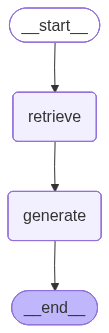

In [36]:
# Display the workflow graph
try:
    from IPython.display import Image, display
    display(Image(rag_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Could not display graph: {e}")
    print("Graph visualization requires graphviz. The workflow will still work fine!")

## 5. Using the RAG Pipeline

Now our RAG pipeline is complete! Let's test it with some questions about Paul Graham's essays.

### Helper Function for Queries

In [37]:
def ask_question(query: str, verbose: bool = True):
    """
    Ask a question using the RAG pipeline.
    
    Args:
        query: The question to ask
        verbose: If True, print retrieval details
    
    Returns:
        The answer and retrieved context
    """
    print("=" * 80)
    print(f"Question: {query}")
    print("=" * 80)
    print()
    
    # Run the workflow
    result = rag_app.invoke({
        "query": query,
        "context": [],
        "answer": ""
    })
    
    # Display results
    if verbose:
        print("\nRetrieved Context:")
        print("-" * 80)
        for i, doc in enumerate(result["context"], 1):
            print(f"\n[{i}] {doc.metadata.get('title', 'Unknown')} ({doc.metadata.get('date', 'Unknown')})")
            print(f"    {doc.page_content[:150]}...")
    
    print("\nAnswer:")
    print("=" * 80)
    print(result["answer"])
    print("\n")
    
    return result

print("Helper function ready")

Helper function ready


### Example Query 1: Startup Ideas

Let's ask about what makes a good startup idea, a common topic in Paul Graham's essays.

In [38]:
result1 = ask_question("What makes a good startup idea according to Paul Graham?")

Question: What makes a good startup idea according to Paul Graham?

Retrieving documents for query: 'What makes a good startup idea according to Paul Graham?'
Retrieved 5 relevant documents
Generating answer using 5 context chunks
Answer generated

Retrieved Context:
--------------------------------------------------------------------------------

[1] How to Get Startup Ideas (November 2012)
    The way to get startup ideas is not to try to think of startup ideas. It's to look for problems, preferably problems you have yourself.

The very best...

[2] How to Start a Startup (March 2005)
    _(This essay is derived from a talk at the Harvard Computer Society.)_

You need three things to create a successful startup: to start with good peopl...

[3] How to Get Startup Ideas (November 2012)
    Made-up startup ideas are usually of the first type. Lots of people are mildly interested in a social network for pet owners.

Nearly all good startup...

[4] How to Get Startup Ideas (November 2012

### Example Query 2: Programming Languages

Paul Graham has written extensively about programming languages, particularly Lisp.

In [39]:
result2 = ask_question("What does Paul Graham think about programming languages?")

Question: What does Paul Graham think about programming languages?

Retrieving documents for query: 'What does Paul Graham think about programming languages?'
Retrieved 5 relevant documents
Generating answer using 5 context chunks
Answer generated

Retrieved Context:
--------------------------------------------------------------------------------

[1] Beating the Averages (April 2003)
    Ordinarily technology changes fast. But programming languages are different: programming languages are not just technology, but what programmers think...

[2] Succinctness is Power (May 2002)
    Brooks' hypothesis, if it's true, seems to be at the very heart of hacking. In the years since, I've paid close attention to any evidence I could get ...

[3] What Languages Fix ()
    Kevin Kelleher suggested an interesting way to compare programming languages: to describe each in terms of the problem it fixes. The surprising thing ...

[4] Beating the Averages (April 2003)
    I'll begin with a shockingly c